In [ ]:
!pip install pennylane pennylane-lightning torch scikit-learn matplotlib seaborn pandas -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 82.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 34.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 41.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 72.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 62.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 8.0 MB/s eta 0:00:00


In [ ]:
%%writefile dataset_loader.py

"""
dataset_loader.py

DatasetLoader for the binary Brain Tumor feature dataset.

Dataset:
    Brain Tumor.csv

Columns:
    Image
    17 numerical features
    Target

Target:
    Target
        0 = Non-Tumor
        1 = Tumor

The Image column is used only as an identifier
and is NOT used as a model feature.
"""

from dataclasses import dataclass

import numpy as np
import pandas as pd
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler



@dataclass
class DatasetBundle:

    X_train: torch.Tensor
    X_test: torch.Tensor

    y_train: torch.Tensor
    y_test: torch.Tensor

    feature_names: list

    n_features: int
    n_classes: int

    scaler: StandardScaler



class DatasetLoader:

    def __init__(
        self,
        csv_path: str,
        test_size: float = 0.20,
        random_state: int = 42
    ):

        self.csv_path = csv_path
        self.test_size = test_size
        self.random_state = random_state

        self._bundle = None



    def _load_raw(self):

        df = pd.read_csv(
            self.csv_path
        )



        feature_names = [

            "Mean",
            "Variance",
            "Standard Deviation",
            "Entropy",
            "Skewness",
            "Kurtosis",

            "Contrast",
            "Energy",
            "ASM",
            "Homogeneity",
            "Dissimilarity",
            "Correlation",
            "Coarseness",

            "PSNR",
            "SSIM",
            "MSE",
            "DC",

        ]



        required_columns = (
            ["Image", "Target"] +
            feature_names
        )

        missing_columns = [
            col
            for col in required_columns
            if col not in df.columns
        ]

        if missing_columns:

            raise ValueError(
                "Missing columns in CSV: "
                + str(missing_columns)
            )



        for col in feature_names:

            df[col] = pd.to_numeric(
                df[col],
                errors="coerce"
            )



        df["Target"] = pd.to_numeric(
            df["Target"],
            errors="coerce"
        )



        before = len(df)

        df = df.dropna(
            subset=feature_names + ["Target"]
        ).reset_index(
            drop=True
        )

        after = len(df)

        removed = before - after

        if removed > 0:

            print(
                f"Removed {removed} rows "
                "containing missing/non-numeric values."
            )


        X = df[
            feature_names
        ].to_numpy(
            dtype=np.float32
        )

        y = df[
            "Target"
        ].to_numpy(
            dtype=np.int64
        )



        unique_classes = np.unique(y)

        if not np.array_equal(
            unique_classes,
            np.array([0, 1])
        ):

            raise ValueError(
                "Expected Target values [0, 1], "
                f"but found {unique_classes.tolist()}"
            )

        return X, y, feature_names


    def load(self):

        X, y, feature_names = self._load_raw()



        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=self.test_size,
            random_state=self.random_state,
            stratify=y
        )



        scaler = StandardScaler()

        X_train = scaler.fit_transform(
            X_train
        )

        X_test = scaler.transform(
            X_test
        )



        X_train = (
            np.tanh(X_train) * np.pi
        )

        X_test = (
            np.tanh(X_test) * np.pi
        )



        bundle = DatasetBundle(

            X_train=torch.tensor(
                X_train,
                dtype=torch.float32
            ),

            X_test=torch.tensor(
                X_test,
                dtype=torch.float32
            ),

            y_train=torch.tensor(
                y_train,
                dtype=torch.long
            ),

            y_test=torch.tensor(
                y_test,
                dtype=torch.long
            ),

            feature_names=feature_names,

            n_features=X.shape[1],

            n_classes=len(
                np.unique(y)
            ),

            scaler=scaler
        )

        self._bundle = bundle

        return bundle



    @property
    def bundle(self):

        if self._bundle is None:

            raise RuntimeError(
                "Call .load() before accessing .bundle"
            )

        return self._bundle



Writing dataset_loader.py


In [ ]:
%%writefile quantum_circuit.py

"""
quantum_circuit.py

Shared VQC circuit.

The raw input can contain all original features.

The feature_order determines which features are actually
encoded into the quantum circuit.

Therefore:

    raw input = 17 features

while:

    encoded features = selected feature count

This allows the proposed method to reduce the number
of re-uploading layers.
"""

import math

import pennylane as qml
import torch


class QuantumCircuit:

    def __init__(
        self,
        n_qubits: int = 8,
        n_features: int = 17,
        n_classes: int = 2,
        input_features: int = 17,
        device_name: str = "default.qubit"
    ):

        self.n_qubits = n_qubits


        self.n_features = n_features


        self.input_features = input_features

        self.n_classes = n_classes



        self.n_layers = math.ceil(
            self.n_features / self.n_qubits
        )



        self.device_name = (
            self._resolve_device(
                device_name
            )
        )

        self.dev = qml.device(
            self.device_name,
            wires=self.n_qubits
        )



        self.weight_shape = (
            self.n_layers + 1,
            self.n_qubits,
            2
        )



        self.qnode = qml.QNode(
            self._circuit,
            self.dev,
            interface="torch",
            diff_method="backprop"
        )



    @staticmethod
    def _resolve_device(
        preferred
    ):

        try:

            qml.device(
                preferred,
                wires=2
            )

            return preferred

        except Exception:

            return "default.qubit"



    def _entangling_layer(self):

        for i in range(
            self.n_qubits
        ):

            qml.CNOT(
                wires=[
                    i,
                    (i + 1) % self.n_qubits
                ]
            )



    def _variational_layer(
        self,
        weights,
        layer_idx
    ):

        for q in range(
            self.n_qubits
        ):

            qml.RY(
                weights[
                    layer_idx,
                    q,
                    0
                ],
                wires=q
            )

            qml.RZ(
                weights[
                    layer_idx,
                    q,
                    1
                ],
                wires=q
            )



    def _encode_chunk(
        self,
        x,
        feature_order,
        layer_idx
    ):

        start = (
            layer_idx
            * self.n_qubits
        )

        chunk = feature_order[
            start:start + self.n_qubits
        ]

        for q, feat_idx in enumerate(
            chunk
        ):

            qml.RX(
                x[..., feat_idx],
                wires=q
            )


    def _circuit(
        self,
        x,
        weights,
        feature_order
    ):

        for layer_idx in range(
            self.n_layers
        ):

            self._encode_chunk(
                x,
                feature_order,
                layer_idx
            )

            self._variational_layer(
                weights,
                layer_idx
            )

            self._entangling_layer()



        self._variational_layer(
            weights,
            self.n_layers
        )

        return [
            qml.expval(
                qml.PauliZ(q)
            )
            for q in range(
                self.n_qubits
            )
        ]



    def draw(
        self,
        x_sample,
        weights_sample,
        feature_order
    ):

        return qml.draw(
            self.qnode
        )(
            x_sample,
            weights_sample,
            feature_order
        )



    def circuit_depth(
        self,
        x_sample,
        weights_sample,
        feature_order
    ):

        with qml.tape.QuantumTape() as tape:

            self._circuit(
                x_sample,
                weights_sample,
                feature_order
            )

        return tape.graph.get_depth()

Writing quantum_circuit.py


In [ ]:
%%writefile sequential_uploader.py
"""
sequential_uploader.py
=======================
Module: SequentialUploader

Implements the BASELINE feature ordering strategy from the original
Data Re-uploading paper (Pérez-Salinas et al., 2020): features are uploaded
strictly in their natural index order, chunked sequentially across
re-uploading layers.

Example (30 features, 8 qubits):
    Layer 1: features 0-7
    Layer 2: features 8-15
    Layer 3: features 16-23
    Layer 4: features 24-29 (padded by wrap-around)
"""

from typing import List


class SequentialUploader:
    """
    Produces the natural, index-ordered feature upload schedule.

    Parameters
    ----------
    n_features : int
        Total number of classical features.
    n_qubits : int
        Number of qubits / chunk size per layer.
    """

    def __init__(self, n_features: int, n_qubits: int):
        self.n_features = n_features
        self.n_qubits = n_qubits

    def get_feature_order(self) -> List[int]:
        """
        Returns feature indices in plain sequential order: [0, 1, 2, ..., N-1],
        padded (by wrap-around, i.e. reusing early indices) so that its length
        is an exact multiple of n_qubits - this lets QuantumCircuit slice it
        into equal-size chunks without any special-casing for the baseline.
        """
        order = list(range(self.n_features))
        n_layers = -(-self.n_features // self.n_qubits)  # ceil division
        padded_len = n_layers * self.n_qubits
        pad_needed = padded_len - self.n_features
        if pad_needed > 0:
            order += order[:pad_needed]
        return order

    def describe(self) -> str:
        return "Sequential Data Re-uploading (natural feature index order, 1-8, 9-16, ...)"


Writing sequential_uploader.py


In [ ]:
%%writefile association_analyzer.py
"""
association_analyzer.py
========================
Module: AssociationAnalyzer

Computes pairwise Pearson correlation between all features and builds an
Association Matrix. Also derives feature groups whose members are strongly
correlated with one another, which the AdaptiveScheduler later uses to keep
associated features close together in the upload order.
"""

import numpy as np
import pandas as pd


class AssociationAnalyzer:
    """
    Parameters
    ----------
    corr_threshold : float
        Absolute Pearson correlation above which two features are considered
        'strongly associated' and grouped together.
    """

    def __init__(self, corr_threshold: float = 0.6):
        self.corr_threshold = corr_threshold
        self.association_matrix: np.ndarray | None = None
        self.groups: list[list[int]] | None = None

    def fit(self, X: np.ndarray) -> "AssociationAnalyzer":
        """
        Computes the Pearson correlation matrix over the feature columns of X.

        Parameters
        ----------
        X : np.ndarray, shape (n_samples, n_features)
        """
        df = pd.DataFrame(X)
        self.association_matrix = df.corr(method="pearson").to_numpy()
        self.groups = self._build_groups(self.association_matrix)
        return self

    def _build_groups(self, corr_matrix: np.ndarray) -> list[list[int]]:
        """
        Greedily groups features into clusters of mutually strongly-correlated
        features using |correlation| >= corr_threshold. Each feature belongs
        to exactly one group (a simple connected-components style grouping).
        """
        n = corr_matrix.shape[0]
        visited = [False] * n
        groups = []

        for i in range(n):
            if visited[i]:
                continue
            group = [i]
            visited[i] = True
            for j in range(n):
                if i != j and not visited[j]:
                    if abs(corr_matrix[i, j]) >= self.corr_threshold:
                        group.append(j)
                        visited[j] = True
            groups.append(group)
        return groups

    def get_association_matrix(self) -> np.ndarray:
        if self.association_matrix is None:
            raise RuntimeError("Call .fit(X) first.")
        return self.association_matrix

    def get_groups(self) -> list[list[int]]:
        if self.groups is None:
            raise RuntimeError("Call .fit(X) first.")
        return self.groups

    def get_partner_strength(self, feature_idx: int) -> float:
        """
        Returns the mean absolute correlation of `feature_idx` with the other
        members of its association group - used by AdaptiveScheduler as a
        tie-breaker / cohesion signal.
        """
        group = next(g for g in self.groups if feature_idx in g)
        others = [g for g in group if g != feature_idx]
        if not others:
            return 0.0
        return float(np.mean([abs(self.association_matrix[feature_idx, o]) for o in others]))


Writing association_analyzer.py


In [ ]:
%%writefile priority_ranker.py

"""
priority_ranker.py

Enhanced feature-priority calculation for the Brain Tumor dataset.

Priority combines:

1. Variance
2. Mutual Information
3. Random Forest importance
4. Class separation

All components are normalized before combination.
"""

import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif


class PriorityRanker:

    def __init__(
        self,
        w_variance: float = 0.10,
        w_mutual_info: float = 0.40,
        w_importance: float = 0.40,
        w_separation: float = 0.10,
        random_state: int = 42
    ):

        self.w_variance = w_variance
        self.w_mutual_info = w_mutual_info
        self.w_importance = w_importance
        self.w_separation = w_separation
        self.random_state = random_state

        self.priority_scores = None

        self.variance_scores = None
        self.mi_scores = None
        self.rf_scores = None
        self.separation_scores = None


    @staticmethod
    def _min_max(arr):

        arr = np.asarray(
            arr,
            dtype=np.float64
        )

        lo = np.min(arr)
        hi = np.max(arr)

        if hi - lo < 1e-12:

            return np.zeros_like(arr)

        return (arr - lo) / (hi - lo)



    @staticmethod
    def _class_separation(X, y):

        class0 = X[y == 0]
        class1 = X[y == 1]

        mean0 = np.mean(
            class0,
            axis=0
        )

        mean1 = np.mean(
            class1,
            axis=0
        )

        std0 = np.std(
            class0,
            axis=0
        )

        std1 = np.std(
            class1,
            axis=0
        )

        pooled_std = np.sqrt(
            (std0 ** 2 + std1 ** 2) / 2.0
            + 1e-12
        )

        separation = np.abs(
            mean1 - mean0
        ) / pooled_std

        return separation



    def fit(
        self,
        X,
        y
    ):

        X = np.asarray(
            X,
            dtype=np.float64
        )

        y = np.asarray(
            y
        )



        variance = np.var(
            X,
            axis=0
        )



        mi = mutual_info_classif(
            X,
            y,
            random_state=self.random_state
        )



        rf = RandomForestClassifier(
            n_estimators=300,
            random_state=self.random_state,
            n_jobs=-1
        )

        rf.fit(
            X,
            y
        )

        importance = rf.feature_importances_



        separation = self._class_separation(
            X,
            y
        )


        variance_n = self._min_max(
            variance
        )

        mi_n = self._min_max(
            mi
        )

        importance_n = self._min_max(
            importance
        )

        separation_n = self._min_max(
            separation
        )



        self.priority_scores = (

            self.w_variance * variance_n

            + self.w_mutual_info * mi_n

            + self.w_importance * importance_n

            + self.w_separation * separation_n
        )

        self.variance_scores = variance_n
        self.mi_scores = mi_n
        self.rf_scores = importance_n
        self.separation_scores = separation_n

        return self


    def get_scores(self):

        if self.priority_scores is None:

            raise RuntimeError(
                "Call .fit(X, y) first."
            )

        return self.priority_scores



    def get_ranked_indices(self):

        return np.argsort(
            -self.get_scores()
        )



    def print_ranking(
        self,
        feature_names=None
    ):

        ranked = self.get_ranked_indices()
        scores = self.get_scores()

        print()
        print(
            "===== FEATURE PRIORITY RANKING ====="
        )

        for rank, idx in enumerate(
            ranked,
            start=1
        ):

            if feature_names is not None:

                name = feature_names[idx]

            else:

                name = f"Feature {idx}"

            print(
                f"{rank:02d}. "
                f"{name:<22} "
                f"score={scores[idx]:.4f}"
            )

Writing priority_ranker.py


In [ ]:
%%writefile adaptive_scheduler.py

"""
adaptive_scheduler.py

Enhanced Association-Guided Priority-Based Adaptive Scheduler.

Main idea:

    High priority
        +
    Low redundancy
        ↓
    selected feature

This makes the proposed system adaptive in two ways:

1. Feature ordering
2. Feature selection

The scheduler then determines how many quantum
encoding layers are actually required.
"""

from typing import List

import numpy as np


class AdaptiveScheduler:

    def __init__(
        self,
        association_analyzer,
        priority_ranker,
        n_qubits: int,
        redundancy_weight: float = 0.35,
        cumulative_threshold: float = 0.92,
        min_features: int = 8,
        max_features: int | None = None
    ):

        self.association_analyzer = (
            association_analyzer
        )

        self.priority_ranker = (
            priority_ranker
        )

        self.n_qubits = n_qubits

        self.redundancy_weight = (
            redundancy_weight
        )

        self.cumulative_threshold = (
            cumulative_threshold
        )

        self.min_features = min_features

        self.max_features = max_features

        self.feature_order: List[int] | None = None

        self.selected_features: List[int] = []

        self.rejected_features: List[int] = []

        self.n_layers = None



    def build_order(self):

        scores = (
            self.priority_ranker
            .get_scores()
        )

        ranked = list(
            self.priority_ranker
            .get_ranked_indices()
        )

        corr = (
            self.association_analyzer
            .get_association_matrix()
        )

        n_features = len(scores)

        if self.max_features is None:

            self.max_features = n_features



        total_priority = np.sum(
            scores
        )

        if total_priority <= 1e-12:

            total_priority = 1.0


        selected = []

        cumulative_priority = 0.0

        for feat in ranked:



            if len(selected) == 0:

                redundancy = 0.0

            else:

                redundancy = max(
                    abs(
                        corr[feat, selected_feat]
                    )
                    for selected_feat
                    in selected
                )



            utility = (
                scores[feat]
                -
                self.redundancy_weight
                * redundancy
            )



            if (
                len(selected)
                < self.min_features
            ):

                selected.append(
                    feat
                )

                cumulative_priority += max(
                    utility,
                    0.0
                )

                continue



            relative_coverage = (
                cumulative_priority
                / total_priority
            )

            if (
                relative_coverage
                >= self.cumulative_threshold
            ):

                break



            if utility > 0:

                selected.append(
                    feat
                )

                cumulative_priority += max(
                    utility,
                    0.0
                )

            if len(selected) >= self.max_features:

                break



        if len(selected) < self.min_features:

            for feat in ranked:

                if feat not in selected:

                    selected.append(
                        feat
                    )

                if len(selected) >= self.min_features:

                    break



        selected = list(
            dict.fromkeys(selected)
        )

        self.selected_features = selected

        self.rejected_features = [
            f
            for f in range(n_features)
            if f not in selected
        ]



        self.n_layers = (
            -(-len(selected) // self.n_qubits)
        )



        padded_order = list(
            selected
        )

        padded_len = (
            self.n_layers
            * self.n_qubits
        )

        pad_needed = (
            padded_len
            - len(padded_order)
        )

        if pad_needed > 0:

            padded_order += (
                selected[:pad_needed]
            )

        self.feature_order = padded_order

        return self.feature_order



    def get_feature_order(self):

        if self.feature_order is None:

            return self.build_order()

        return self.feature_order



    def describe(self):

        return (
            "Association-Guided "
            "Priority + Redundancy Adaptive "
            "Data Re-uploading"
        )

    def summary(self):

        print()
        print(
            "===== ADAPTIVE SCHEDULER ====="
        )

        print(
            "Selected features:",
            self.selected_features
        )

        print(
            "Number selected:",
            len(self.selected_features)
        )

        print(
            "Rejected features:",
            self.rejected_features
        )

        print(
            "Re-uploading layers:",
            self.n_layers
        )

        print(
            "Final padded order:",
            self.feature_order
        )

Writing adaptive_scheduler.py


In [ ]:
%%writefile vqc_model.py

"""
vqc_model.py

VQC model supporting adaptive feature selection.

Raw input:
    17 features

Quantum circuit:
    selected subset of those features

This permits the proposed method to use fewer
re-uploading layers while receiving the same raw input.
"""

from typing import List

import torch
import torch.nn as nn

from quantum_circuit import QuantumCircuit


class VQCModel(nn.Module):

    def __init__(
        self,
        quantum_circuit: QuantumCircuit,
        feature_order: List[int],
        n_classes: int = 2
    ):

        super().__init__()

        self.qc = quantum_circuit

        self.feature_order = list(
            feature_order
        )

        self.register_buffer(
            "feature_order_tensor",
            torch.tensor(
                self.feature_order,
                dtype=torch.long
            )
        )


        self.weights = nn.Parameter(
            0.1
            * torch.randn(
                self.qc.weight_shape,
                dtype=torch.float32
            )
        )



        self.readout = nn.Linear(
            self.qc.n_qubits,
            n_classes
        )


    def _run_batch_circuit(
        self,
        X
    ):

        X = X.to(
            dtype=torch.float32
        )

        expvals = self.qc.qnode(
            X,
            self.weights,
            self.feature_order
        )

        if isinstance(
            expvals,
            (list, tuple)
        ):

            expvals = torch.stack(
                expvals,
                dim=-1
            )

        else:

            expvals = torch.as_tensor(
                expvals,
                dtype=torch.float32
            )

            if expvals.ndim == 1:

                expvals = expvals.unsqueeze(
                    -1
                )

        return expvals.to(
            dtype=torch.float32
        )


    def forward(
        self,
        X
    ):

        if not isinstance(
            X,
            torch.Tensor
        ):

            X = torch.tensor(
                X,
                dtype=torch.float32
            )

        X = X.to(
            dtype=torch.float32
        )



        if X.ndim == 1:

            X = X.unsqueeze(
                0
            )



        if X.ndim != 2:

            raise ValueError(
                "X must have shape "
                "(batch_size, input_features)."
            )

        if X.shape[1] != self.qc.input_features:

            raise ValueError(
                f"Expected {self.qc.input_features} "
                f"input features, received "
                f"{X.shape[1]}."
            )



        expvals = self._run_batch_circuit(
            X
        )



        logits = self.readout(
            expvals
        )

        return logits.to(
            dtype=torch.float32
        )



    def count_trainable_parameters(
        self
    ):

        return sum(
            p.numel()
            for p in self.parameters()
            if p.requires_grad
        )

Writing vqc_model.py


In [ ]:
import importlib

import priority_ranker
import adaptive_scheduler
import quantum_circuit
import vqc_model

importlib.reload(priority_ranker)
importlib.reload(adaptive_scheduler)
importlib.reload(quantum_circuit)
importlib.reload(vqc_model)

from priority_ranker import PriorityRanker
from adaptive_scheduler import AdaptiveScheduler
from quantum_circuit import QuantumCircuit
from vqc_model import VQCModel

print("Enhanced adaptive VQC modules loaded.")

Enhanced adaptive VQC modules loaded.


In [ ]:
%%writefile trainer.py
"""
trainer.py
===========
Module: Trainer

Handles mini-batch training of a VQCModel using Adam + CrossEntropyLoss with
early stopping, for BOTH the Baseline and Proposed models (identical training
procedure, so the comparison isolates the effect of feature ordering).
"""

import time
import copy
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


class Trainer:
    """
    Parameters
    ----------
    model : VQCModel
    lr : float
        Adam learning rate.
    batch_size : int
    max_epochs : int
    patience : int
        Number of epochs without validation-loss improvement before stopping.
    """

    def __init__(self, model, lr: float = 0.05, batch_size: int = 16,
                 max_epochs: int = 30, patience: int = 5):
        self.model = model
        self.lr = lr
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=self.lr)
        self.criterion = nn.CrossEntropyLoss()
        self.history = {"train_loss": [], "val_loss": [], "val_acc": []}
        self.training_time_sec = None

    def fit(self, X_train, y_train, X_val, y_val):
        """
        Trains the model with early stopping on validation loss.

        Returns
        -------
        history : dict with 'train_loss', 'val_loss', 'val_acc' per epoch.
        """
        dataset = TensorDataset(X_train, y_train)
        loader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        best_val_loss = float("inf")
        epochs_no_improve = 0
        best_state = copy.deepcopy(self.model.state_dict())

        start = time.time()
        for epoch in range(self.max_epochs):
            self.model.train()
            epoch_loss = 0.0
            for xb, yb in loader:
                self.optimizer.zero_grad()
                logits = self.model(xb)
                loss = self.criterion(logits, yb)
                loss.backward()
                self.optimizer.step()
                epoch_loss += loss.item() * xb.size(0)
            train_loss = epoch_loss / len(dataset)

            self.model.eval()
            with torch.no_grad():
                val_logits = self.model(X_val)
                val_loss = self.criterion(val_logits, y_val).item()
                val_preds = torch.argmax(val_logits, dim=1)
                val_acc = (val_preds == y_val).float().mean().item()

            self.history["train_loss"].append(train_loss)
            self.history["val_loss"].append(val_loss)
            self.history["val_acc"].append(val_acc)

            print(f"Epoch {epoch + 1:02d}/{self.max_epochs} | "
                  f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
                  f"val_acc={val_acc:.4f}")

            if val_loss < best_val_loss - 1e-4:
                best_val_loss = val_loss
                epochs_no_improve = 0
                best_state = copy.deepcopy(self.model.state_dict())
            else:
                epochs_no_improve += 1
                if epochs_no_improve >= self.patience:
                    print(f"Early stopping triggered at epoch {epoch + 1}.")
                    break

        self.model.load_state_dict(best_state)
        self.training_time_sec = time.time() - start
        return self.history

    def get_training_time(self) -> float:
        if self.training_time_sec is None:
            raise RuntimeError("Call .fit(...) first.")
        return self.training_time_sec


Writing trainer.py


In [ ]:
import importlib
import vqc_model

importlib.reload(vqc_model)

from vqc_model import VQCModel

print("Updated VQCModel loaded successfully")

Updated VQCModel loaded successfully


In [ ]:
%%writefile evaluator.py
"""
evaluator.py
=============
Module: Evaluator

Computes the full evaluation suite for a trained VQCModel:
  Accuracy, Precision, Recall, F1, Confusion Matrix, ROC Curve,
  Classification Report, Inference Time, Circuit Depth,
  Number of Re-uploading Layers, Number of Trainable Parameters.
"""

import time
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc, classification_report,
)


class Evaluator:
    """
    Parameters
    ----------
    model : VQCModel
        A trained model.
    """

    def __init__(self, model):
        self.model = model
        self.results: dict = {}

    def evaluate(self, X_test: torch.Tensor, y_test: torch.Tensor) -> dict:
        """
        Runs inference on the test set and computes all required metrics.

        Returns
        -------
        results : dict
        """
        self.model.eval()
        start = time.time()
        with torch.no_grad():
            logits = self.model(X_test)
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(logits, dim=1)
        inference_time = time.time() - start

        y_true = y_test.numpy()
        y_pred = preds.numpy()
        y_score = probs[:, 1].numpy()  # positive-class probability

        fpr, tpr, _ = roc_curve(y_true, y_score)
        roc_auc = auc(fpr, tpr)

        self.results = {
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1_score": f1_score(y_true, y_pred, zero_division=0),
            "confusion_matrix": confusion_matrix(y_true, y_pred),
            "roc_fpr": fpr,
            "roc_tpr": tpr,
            "roc_auc": roc_auc,
            "classification_report": classification_report(y_true, y_pred, zero_division=0),
            "inference_time_sec": inference_time,
            "inference_time_per_sample_ms": (inference_time / len(y_true)) * 1000,
            "n_trainable_params": self.model.count_trainable_parameters(),
            "n_reupload_layers": self.model.qc.n_layers,
        }
        return self.results

    def compute_circuit_depth(self, x_sample: torch.Tensor) -> int:
        depth = self.model.qc.circuit_depth(
            x_sample, self.model.weights, self.model.feature_order
        )
        self.results["circuit_depth"] = depth
        return depth

    def summary(self) -> str:
        if not self.results:
            raise RuntimeError("Call .evaluate(...) first.")
        r = self.results
        lines = [
            f"Accuracy            : {r['accuracy']:.4f}",
            f"Precision            : {r['precision']:.4f}",
            f"Recall               : {r['recall']:.4f}",
            f"F1 Score             : {r['f1_score']:.4f}",
            f"ROC AUC              : {r['roc_auc']:.4f}",
            f"Inference Time (ms/sample): {r['inference_time_per_sample_ms']:.4f}",
            f"Trainable Parameters : {r['n_trainable_params']}",
            f"Re-uploading Layers  : {r['n_reupload_layers']}",
        ]
        if "circuit_depth" in r:
            lines.append(f"Circuit Depth        : {r['circuit_depth']}")
        return "\n".join(lines)


Writing evaluator.py


In [ ]:
%%writefile comparator.py
"""
comparator.py
==============
Module: Comparator

Produces side-by-side comparison tables and plots between the Baseline
(Sequential) and Proposed (Association-Guided Priority-Based Adaptive)
methods: Accuracy, Precision, Recall, F1, Training Time, Inference Time,
Circuit Depth, Number of Re-uploading Layers, Memory Usage; plus Bar Charts,
Training Curves, Confusion Matrices, and Depth/Time comparison plots.
"""

import tracemalloc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


class Comparator:
    """
    Parameters
    ----------
    baseline_name, proposed_name : str
        Display labels used across every table and plot.
    """

    def __init__(self, baseline_name: str = "Sequential (Baseline)",
                 proposed_name: str = "Association-Guided Adaptive (Proposed)"):
        self.baseline_name = baseline_name
        self.proposed_name = proposed_name

    def build_table(self, baseline_results: dict, proposed_results: dict,
                     baseline_train_time: float, proposed_train_time: float,
                     baseline_mem_mb: float, proposed_mem_mb: float) -> pd.DataFrame:
        """Builds the master comparison DataFrame."""
        rows = {
            "Accuracy": (baseline_results["accuracy"], proposed_results["accuracy"]),
            "Precision": (baseline_results["precision"], proposed_results["precision"]),
            "Recall": (baseline_results["recall"], proposed_results["recall"]),
            "F1 Score": (baseline_results["f1_score"], proposed_results["f1_score"]),
            "ROC AUC": (baseline_results["roc_auc"], proposed_results["roc_auc"]),
            "Training Time (s)": (baseline_train_time, proposed_train_time),
            "Inference Time (ms/sample)": (
                baseline_results["inference_time_per_sample_ms"],
                proposed_results["inference_time_per_sample_ms"],
            ),
            "Circuit Depth": (
                baseline_results.get("circuit_depth", np.nan),
                proposed_results.get("circuit_depth", np.nan),
            ),
            "Re-uploading Layers": (
                baseline_results["n_reupload_layers"],
                proposed_results["n_reupload_layers"],
            ),
            "Trainable Parameters": (
                baseline_results["n_trainable_params"],
                proposed_results["n_trainable_params"],
            ),
            "Peak Memory (MB)": (baseline_mem_mb, proposed_mem_mb),
        }
        df = pd.DataFrame(rows, index=[self.baseline_name, self.proposed_name]).T
        return df

    def plot_bar_comparison(self, df: pd.DataFrame, metrics: list,
                             title: str = "Metric Comparison"):
        subset = df.loc[metrics]
        ax = subset.plot(kind="bar", figsize=(9, 5))
        ax.set_title(title)
        ax.set_ylabel("Score")
        plt.xticks(rotation=20)
        plt.tight_layout()
        plt.show()

    def plot_training_curves(self, baseline_history: dict, proposed_history: dict):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

        axes[0].plot(baseline_history["train_loss"], label=self.baseline_name)
        axes[0].plot(proposed_history["train_loss"], label=self.proposed_name)
        axes[0].set_title("Training Loss")
        axes[0].set_xlabel("Epoch")
        axes[0].set_ylabel("Loss")
        axes[0].legend()

        axes[1].plot(baseline_history["val_acc"], label=self.baseline_name)
        axes[1].plot(proposed_history["val_acc"], label=self.proposed_name)
        axes[1].set_title("Validation Accuracy")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Accuracy")
        axes[1].legend()

        plt.tight_layout()
        plt.show()

    def plot_confusion_matrices(self, baseline_cm, proposed_cm):
        fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
        sns.heatmap(baseline_cm, annot=True, fmt="d", cmap="Blues", ax=axes[0])
        axes[0].set_title(self.baseline_name)
        axes[0].set_xlabel("Predicted")
        axes[0].set_ylabel("Actual")

        sns.heatmap(proposed_cm, annot=True, fmt="d", cmap="Greens", ax=axes[1])
        axes[1].set_title(self.proposed_name)
        axes[1].set_xlabel("Predicted")
        axes[1].set_ylabel("Actual")

        plt.tight_layout()
        plt.show()

    def plot_roc_curves(self, baseline_results: dict, proposed_results: dict):
        plt.figure(figsize=(6, 5))
        plt.plot(baseline_results["roc_fpr"], baseline_results["roc_tpr"],
                  label=f"{self.baseline_name} (AUC={baseline_results['roc_auc']:.3f})")
        plt.plot(proposed_results["roc_fpr"], proposed_results["roc_tpr"],
                  label=f"{self.proposed_name} (AUC={proposed_results['roc_auc']:.3f})")
        plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title("ROC Curve Comparison")
        plt.legend()
        plt.tight_layout()
        plt.show()

    def plot_depth_and_time(self, df: pd.DataFrame):
        fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
        df.loc[["Circuit Depth"]].plot(kind="bar", ax=axes[0], legend=True)
        axes[0].set_title("Circuit Depth Comparison")
        axes[0].set_ylabel("Depth")

        df.loc[["Training Time (s)"]].plot(kind="bar", ax=axes[1], legend=True, color=["#4C72B0", "#DD8452"])
        axes[1].set_title("Training Time Comparison")
        axes[1].set_ylabel("Seconds")

        plt.tight_layout()
        plt.show()


class MemoryTracker:
    """Small helper context manager used by main.py to measure peak memory (MB)."""

    def __enter__(self):
        tracemalloc.start()
        return self

    def __exit__(self, exc_type, exc_val, exc_tb):
        _, peak = tracemalloc.get_traced_memory()
        self.peak_mb = peak / (1024 * 1024)
        tracemalloc.stop()


Writing comparator.py


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import torch

from dataset_loader import DatasetLoader
from quantum_circuit import QuantumCircuit
from sequential_uploader import SequentialUploader
from association_analyzer import AssociationAnalyzer
from priority_ranker import PriorityRanker
from adaptive_scheduler import AdaptiveScheduler
from vqc_model import VQCModel
from trainer import Trainer
from evaluator import Evaluator
from comparator import Comparator, MemoryTracker



N_QUBITS = 8

RANDOM_STATE = 42

MAX_EPOCHS = 30

BATCH_SIZE = 16

PATIENCE = 5




torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)




loader = DatasetLoader(
    csv_path="/content/drive/MyDrive/bd.csv",
    test_size=0.20,
    random_state=RANDOM_STATE
)

bundle = loader.load()




X_train = bundle.X_train
y_train = bundle.y_train

X_test = bundle.X_test
y_test = bundle.y_test




n_features = bundle.n_features
n_classes = bundle.n_classes


print("==============================================")
print("BRAIN TUMOR DATASET")
print("==============================================")

print(f"n_features = {n_features}")
print(f"n_classes  = {n_classes}")
print(f"train_size = {len(X_train)}")
print(f"test_size  = {len(X_test)}")

print()
print("Feature names:")
print(bundle.feature_names)

print()
print("Training classes:")
print(torch.unique(y_train).tolist())

BRAIN TUMOR DATASET
n_features = 17
n_classes  = 2
train_size = 9011
test_size  = 2253

Feature names:
['Mean', 'Variance', 'Standard Deviation', 'Entropy', 'Skewness', 'Kurtosis', 'Contrast', 'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation', 'Coarseness', 'PSNR', 'SSIM', 'MSE', 'DC']

Training classes:
[0, 1]


In [ ]:
from sklearn.model_selection import train_test_split



X_train, X_val, y_train, y_val = train_test_split(
    bundle.X_train,
    bundle.y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=bundle.y_train
)

X_test = bundle.X_test
y_test = bundle.y_test

print("Training samples   :", len(X_train))
print("Validation samples :", len(X_val))
print("Test samples       :", len(X_test))

Training samples   : 7208
Validation samples : 1803
Test samples       : 2253


In [ ]:
seq_uploader = SequentialUploader(n_features=n_features, n_qubits=N_QUBITS)
seq_order = seq_uploader.get_feature_order()
print("Baseline feature order (first 16):", seq_order[:16])
print(seq_uploader.describe())

Baseline feature order (first 16): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
Sequential Data Re-uploading (natural feature index order, 1-8, 9-16, ...)


In [ ]:
def run_pipeline(
    feature_order,
    uploader_label
):



    encoded_features = len(
        set(feature_order)
    )

    print()
    print("=" * 70)
    print(uploader_label)
    print("=" * 70)

    print(
        "Raw input features      :",
        n_features
    )

    print(
        "Encoded real features   :",
        encoded_features
    )

    print(
        "Feature order            :",
        feature_order
    )


    qc = QuantumCircuit(
        n_qubits=N_QUBITS,
        n_features=encoded_features,
        n_classes=n_classes,
        input_features=n_features
    )


    model = VQCModel(
        quantum_circuit=qc,
        feature_order=feature_order,
        n_classes=n_classes
    )

    print(
        "Quantum qubits           :",
        N_QUBITS
    )

    print(
        "Re-uploading layers      :",
        qc.n_layers
    )

    print(
        "Trainable parameters     :",
        model.count_trainable_parameters()
    )



    print(
        "Training samples         :",
        len(X_train)
    )

    print(
        "Validation samples       :",
        len(X_val)
    )

    print(
        "Test samples             :",
        len(X_test)
    )



    trainer = Trainer(
        model=model,
        lr=0.05,
        batch_size=BATCH_SIZE,
        max_epochs=MAX_EPOCHS,
        patience=PATIENCE
    )



    print()
    print(
        f"Starting {uploader_label} training..."
    )

    with MemoryTracker() as mem:

        history = trainer.fit(
            X_train,
            y_train,
            X_val,
            y_val
        )

    training_time = (
        trainer.get_training_time()
    )



    print()
    print(
        f"Evaluating {uploader_label}..."
    )

    evaluator = Evaluator(
        model
    )

    results = evaluator.evaluate(
        X_test,
        y_test
    )



    evaluator.compute_circuit_depth(
        X_test[0]
    )



    print()
    print(
        f"=== {uploader_label}: "
        f"Circuit Diagram ==="
    )

    print(
        qc.draw(
            X_test[0],
            model.weights,
            feature_order
        )
    )



    print()
    print(
        f"=== {uploader_label}: "
        f"Evaluation Summary ==="
    )

    print(
        evaluator.summary()
    )

    print()
    print(
        "Classification Report:"
    )

    print(
        results["classification_report"]
    )



    return {

        "model": model,

        "history": history,

        "results": results,

        "training_time": training_time,

        "peak_mem_mb": mem.peak_mb,

        "feature_order": feature_order,

        "encoded_features": encoded_features,

        "n_layers": qc.n_layers,

        "circuit_depth": results.get(
            "circuit_depth",
            None
        ),

        "uploader_label": uploader_label
    }

In [ ]:
seq_uploader = SequentialUploader(
    n_features=17,
    n_qubits=8
)

seq_order = seq_uploader.get_feature_order()

baseline_out = run_pipeline(
    seq_order,
    "BASELINE - Sequential"
)


BASELINE - Sequential
Raw input features      : 17
Encoded real features   : 17
Feature order            : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 0, 1, 2, 3, 4, 5, 6]
Quantum qubits           : 8
Re-uploading layers      : 3
Trainable parameters     : 82
Training samples         : 7208
Validation samples       : 1803
Test samples             : 2253

Starting BASELINE - Sequential training...
Epoch 01/30 | train_loss=0.4285 | val_loss=0.3647 | val_acc=0.8436
Epoch 02/30 | train_loss=0.3542 | val_loss=0.3486 | val_acc=0.8602
Epoch 03/30 | train_loss=0.3426 | val_loss=0.3356 | val_acc=0.8619
Epoch 04/30 | train_loss=0.3466 | val_loss=0.3038 | val_acc=0.9007
Epoch 05/30 | train_loss=0.3415 | val_loss=0.3288 | val_acc=0.8663
Epoch 06/30 | train_loss=0.3367 | val_loss=0.3217 | val_acc=0.8796
Epoch 07/30 | train_loss=0.3269 | val_loss=0.2871 | val_acc=0.8796
Epoch 08/30 | train_loss=0.3268 | val_loss=0.2895 | val_acc=0.8935
Epoch 09/30 | train_loss=0.3204 | val_loss=0.323

In [ ]:
X_train_np = X_train.numpy()
y_train_np = y_train.numpy()

assoc = AssociationAnalyzer(
    corr_threshold=0.60
)

assoc.fit(X_train_np)

print("Association analysis completed.")

Association analysis completed.


In [ ]:
ranker = PriorityRanker(
    w_variance=0.10,
    w_mutual_info=0.40,
    w_importance=0.40,
    w_separation=0.10,
    random_state=RANDOM_STATE
)

ranker.fit(
    X_train_np,
    y_train_np
)

print("Priority ranking completed.")

print(
    "Top features:",
    ranker.get_ranked_indices()
)

Priority ranking completed.
Top features: [ 6 13  2 15  1  5 12  0 16 10  4 11  9  3 14  7  8]


In [ ]:
scheduler = AdaptiveScheduler(
    association_analyzer=assoc,
    priority_ranker=ranker,
    n_qubits=N_QUBITS,
    redundancy_weight=0.35,
    cumulative_threshold=0.92,
    min_features=8,
    max_features=16
)

adaptive_order = scheduler.build_order()

print("Adaptive order created:")
print(adaptive_order)

scheduler.summary()

Adaptive order created:
[np.int64(6), np.int64(13), np.int64(2), np.int64(15), np.int64(1), np.int64(5), np.int64(12), np.int64(0), np.int64(16), np.int64(10), np.int64(11), np.int64(6), np.int64(13), np.int64(2), np.int64(15), np.int64(1)]

===== ADAPTIVE SCHEDULER =====
Selected features: [np.int64(6), np.int64(13), np.int64(2), np.int64(15), np.int64(1), np.int64(5), np.int64(12), np.int64(0), np.int64(16), np.int64(10), np.int64(11)]
Number selected: 11
Rejected features: [3, 4, 7, 8, 9, 14]
Re-uploading layers: 2
Final padded order: [np.int64(6), np.int64(13), np.int64(2), np.int64(15), np.int64(1), np.int64(5), np.int64(12), np.int64(0), np.int64(16), np.int64(10), np.int64(11), np.int64(6), np.int64(13), np.int64(2), np.int64(15), np.int64(1)]


In [ ]:
proposed_out = run_pipeline(
    adaptive_order,
    "PROPOSED - Association + Priority + Redundancy Adaptive"
)


PROPOSED - Association + Priority + Redundancy Adaptive
Raw input features      : 17
Encoded real features   : 11
Feature order            : [np.int64(6), np.int64(13), np.int64(2), np.int64(15), np.int64(1), np.int64(5), np.int64(12), np.int64(0), np.int64(16), np.int64(10), np.int64(11), np.int64(6), np.int64(13), np.int64(2), np.int64(15), np.int64(1)]
Quantum qubits           : 8
Re-uploading layers      : 2
Trainable parameters     : 66
Training samples         : 7208
Validation samples       : 1803
Test samples             : 2253

Starting PROPOSED - Association + Priority + Redundancy Adaptive training...
Epoch 01/30 | train_loss=0.3522 | val_loss=0.2933 | val_acc=0.8930
Epoch 02/30 | train_loss=0.3111 | val_loss=0.2785 | val_acc=0.8891
Epoch 03/30 | train_loss=0.3012 | val_loss=0.2731 | val_acc=0.8963
Epoch 04/30 | train_loss=0.3070 | val_loss=0.2853 | val_acc=0.8857
Epoch 05/30 | train_loss=0.3052 | val_loss=0.3231 | val_acc=0.8785
Epoch 06/30 | train_loss=0.2972 | val_loss=0

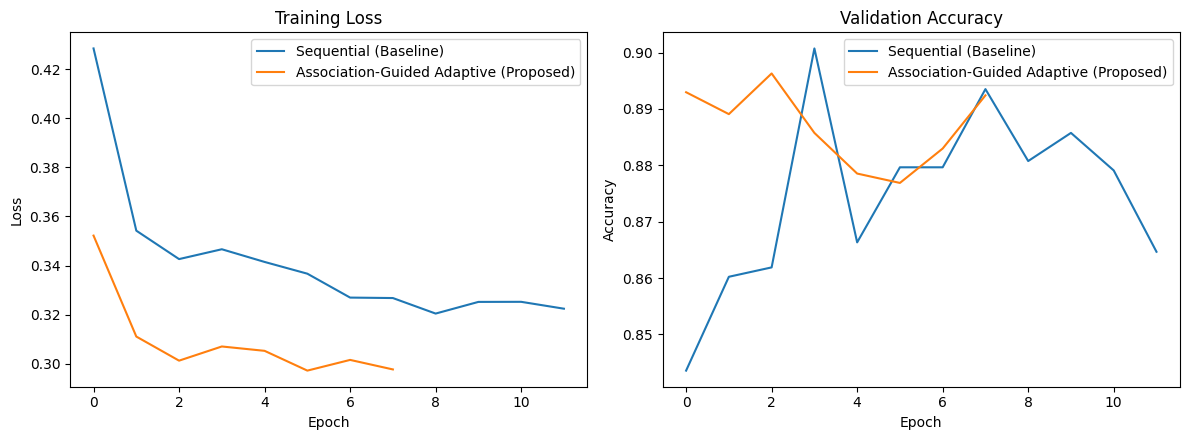

In [ ]:
from comparator import Comparator
comparator = Comparator()
comparator.plot_training_curves(baseline_out["history"], proposed_out["history"])

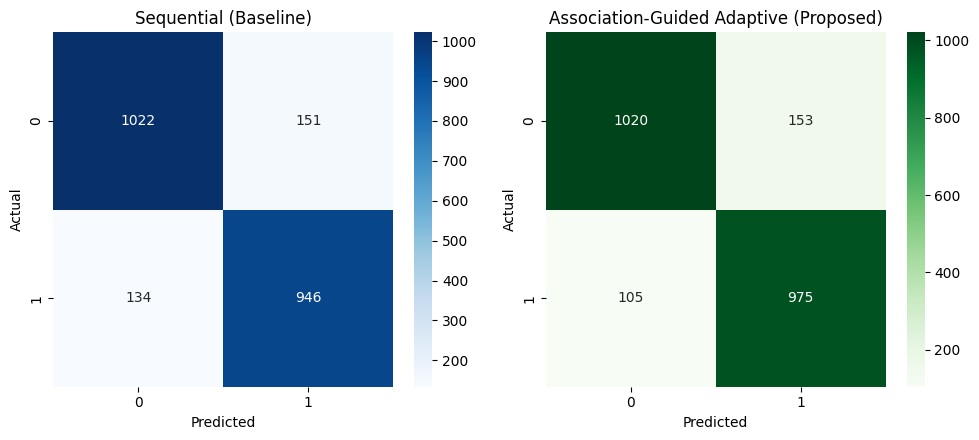

In [ ]:
comparator.plot_confusion_matrices(
    baseline_out["results"]["confusion_matrix"],
    proposed_out["results"]["confusion_matrix"],
)

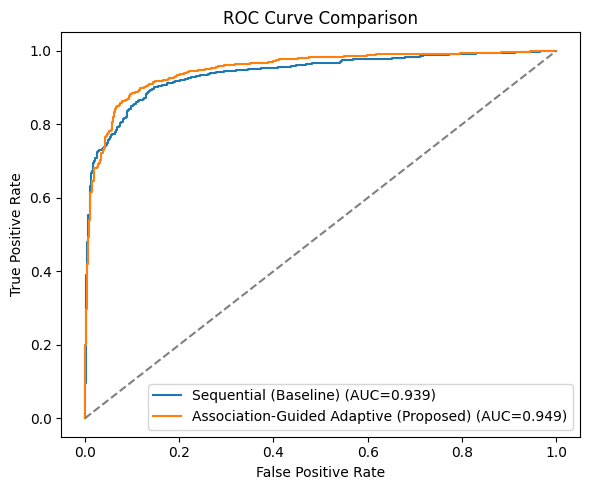

In [ ]:
comparator.plot_roc_curves(baseline_out["results"], proposed_out["results"])

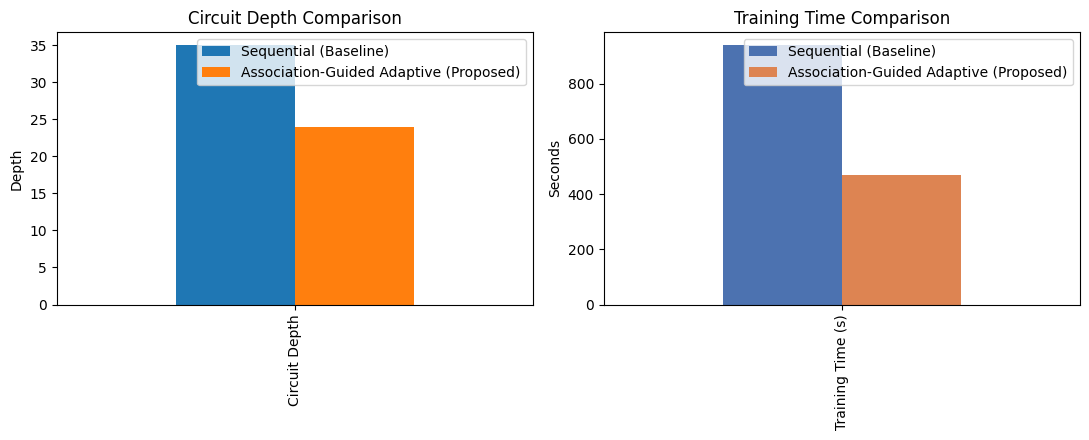

In [ ]:
table = comparator.build_table(
    baseline_out["results"],
    proposed_out["results"],
    baseline_out["training_time"],
    proposed_out["training_time"],
    baseline_out["peak_mem_mb"],
    proposed_out["peak_mem_mb"]
)
comparator.plot_depth_and_time(table)

In [ ]:
print("==============================================")
print("BASELINE vs PROPOSED")
print("==============================================")

print(
    "Baseline accuracy:",
    baseline_out["results"]["accuracy"]
)

print(
    "Proposed accuracy:",
    proposed_out["results"]["accuracy"]
)

print(
    "Baseline F1:",
    baseline_out["results"].get("f1_score",
                                baseline_out["results"].get("f1_macro"))
)

print(
    "Proposed F1:",
    proposed_out["results"].get("f1_score",
                                proposed_out["results"].get("f1_macro"))
)

BASELINE vs PROPOSED
Baseline accuracy: 0.8735019973368842
Proposed accuracy: 0.8854860186418109
Baseline F1: 0.8690858980248047
Proposed F1: 0.8831521739130435


In [ ]:
print("==============================================")
print("FEATURE ORDERS")
print("==============================================")

print("Baseline order:")
print(seq_order)

print()

print("Proposed order:")
print(adaptive_order)

print()

print("Selected features:")
print(scheduler.selected_features)

print()

print("Rejected features:")
print(scheduler.rejected_features)

print()

print("Baseline encoded features:",
      len(set(seq_order)))

print("Proposed encoded features:",
      len(scheduler.selected_features))

print()

print("Baseline layers:",
      baseline_out["results"]["n_reupload_layers"])

print("Proposed layers:",
      proposed_out["results"]["n_reupload_layers"])

FEATURE ORDERS
Baseline order:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 0, 1, 2, 3, 4, 5, 6]

Proposed order:
[np.int64(6), np.int64(13), np.int64(2), np.int64(15), np.int64(1), np.int64(5), np.int64(12), np.int64(0), np.int64(16), np.int64(10), np.int64(11), np.int64(6), np.int64(13), np.int64(2), np.int64(15), np.int64(1)]

Selected features:
[np.int64(6), np.int64(13), np.int64(2), np.int64(15), np.int64(1), np.int64(5), np.int64(12), np.int64(0), np.int64(16), np.int64(10), np.int64(11)]

Rejected features:
[3, 4, 7, 8, 9, 14]

Baseline encoded features: 17
Proposed encoded features: 11

Baseline layers: 3
Proposed layers: 2


In [ ]:
comparator = Comparator()

table = comparator.build_table(
    baseline_out["results"],
    proposed_out["results"],
    baseline_out["training_time"],
    proposed_out["training_time"],
    baseline_out["peak_mem_mb"],
    proposed_out["peak_mem_mb"]
)

print("==============================================")
print("FINAL COMPARISON TABLE")
print("==============================================")

display(
    table.round(4)
)

FINAL COMPARISON TABLE


,Sequential (Baseline),Association-Guided Adaptive (Proposed)
Accuracy,0.8735,0.8855
Precision,0.8624,0.8644
Recall,0.8759,0.9028
F1 Score,0.8691,0.8832
ROC AUC,0.9390,0.9495
Training Time (s),938.2843,468.7073
Inference Time (ms/sample),0.5372,0.3745
Circuit Depth,35.0000,24.0000
Re-uploading Layers,3.0000,2.0000
Trainable Parameters,82.0000,66.0000


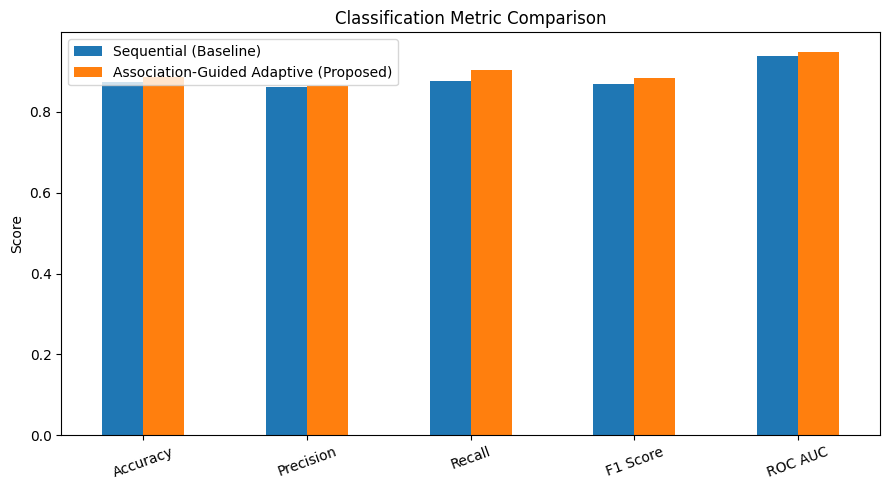

In [ ]:
comparator.plot_bar_comparison(
    table, ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"],
    title="Classification Metric Comparison",
)

In [ ]:


import os
import cv2
import numpy as np
import pandas as pd
import torch

from scipy.stats import skew, kurtosis

from skimage.feature import graycomatrix, graycoprops
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

print("Prediction libraries loaded successfully.")

Prediction libraries loaded successfully.


In [ ]:


FEATURE_NAMES = [
    "Mean",
    "Variance",
    "Standard Deviation",
    "Entropy",
    "Skewness",
    "Kurtosis",
    "Contrast",
    "Energy",
    "ASM",
    "Homogeneity",
    "Dissimilarity",
    "Correlation",
    "Coarseness",
    "PSNR",
    "SSIM",
    "MSE",
    "DC"
]

print("Number of features:", len(FEATURE_NAMES))

for i, feature in enumerate(FEATURE_NAMES, 1):
    print(f"{i:2d}. {feature}")

Number of features: 17
 1. Mean
 2. Variance
 3. Standard Deviation
 4. Entropy
 5. Skewness
 6. Kurtosis
 7. Contrast
 8. Energy
 9. ASM
10. Homogeneity
11. Dissimilarity
12. Correlation
13. Coarseness
14. PSNR
15. SSIM
16. MSE
17. DC


In [ ]:


IMG_SIZE = (224, 224)


def preprocess_prediction_image(image_path):

    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(
            f"Unable to read image: {image_path}"
        )

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    gray = cv2.resize(
        gray,
        IMG_SIZE,
        interpolation=cv2.INTER_AREA
    )

    return gray


print("MRI preprocessing function ready.")

MRI preprocessing function ready.


In [ ]:


def extract_prediction_features(image_path):

    gray = preprocess_prediction_image(
        image_path
    )

    image_float = gray.astype(
        np.float64
    )

    # --------------------------------------------------------
    # 1. Mean
    # --------------------------------------------------------

    mean_value = np.mean(
        image_float
    )

    # --------------------------------------------------------
    # 2. Variance
    # --------------------------------------------------------

    variance_value = np.var(
        image_float
    )

    # --------------------------------------------------------
    # 3. Standard Deviation
    # --------------------------------------------------------

    std_value = np.std(
        image_float
    )

    # --------------------------------------------------------
    # 4. Skewness
    # --------------------------------------------------------

    skewness_value = skew(
        image_float.flatten(),
        bias=False
    )

    # --------------------------------------------------------
    # 5. Kurtosis
    # --------------------------------------------------------

    kurtosis_value = kurtosis(
        image_float.flatten(),
        bias=False
    )

    # --------------------------------------------------------
    # 6. Entropy
    # --------------------------------------------------------

    histogram = cv2.calcHist(
        [gray],
        [0],
        None,
        [256],
        [0, 256]
    ).flatten()

    probability = histogram / (
        histogram.sum() + 1e-12
    )

    probability = probability[
        probability > 0
    ]

    entropy_value = -np.sum(
        probability *
        np.log2(probability)
    )

    # --------------------------------------------------------
    # GLCM
    # --------------------------------------------------------

    gray_32 = (
        gray / 8
    ).astype(np.uint8)

    glcm = graycomatrix(
        gray_32,
        distances=[1],
        angles=[0],
        levels=32,
        symmetric=True,
        normed=True
    )

    # --------------------------------------------------------
    # 7. Contrast
    # --------------------------------------------------------

    contrast_value = graycoprops(
        glcm,
        "contrast"
    )[0, 0]

    # --------------------------------------------------------
    # 8. Dissimilarity
    # --------------------------------------------------------

    dissimilarity_value = graycoprops(
        glcm,
        "dissimilarity"
    )[0, 0]

    # --------------------------------------------------------
    # 9. Homogeneity
    # --------------------------------------------------------

    homogeneity_value = graycoprops(
        glcm,
        "homogeneity"
    )[0, 0]

    # --------------------------------------------------------
    # 10. Correlation
    # --------------------------------------------------------

    correlation_value = graycoprops(
        glcm,
        "correlation"
    )[0, 0]

    # --------------------------------------------------------
    # 11. ASM
    # --------------------------------------------------------

    asm_value = graycoprops(
        glcm,
        "ASM"
    )[0, 0]

    # --------------------------------------------------------
    # 12. Energy
    # --------------------------------------------------------

    energy_value = graycoprops(
        glcm,
        "energy"
    )[0, 0]

    # --------------------------------------------------------
    # 13. Coarseness
    # --------------------------------------------------------

    kernel_size = 5

    local_mean = cv2.blur(
        image_float,
        (kernel_size, kernel_size)
    )

    local_variance = (
        cv2.blur(
            image_float ** 2,
            (kernel_size, kernel_size)
        )
        - local_mean ** 2
    )

    coarseness_value = np.mean(
        np.sqrt(
            np.maximum(
                local_variance,
                0
            )
        )
    )

    # --------------------------------------------------------
    # 14. MSE
    # --------------------------------------------------------

    blurred = cv2.GaussianBlur(
        gray,
        (5, 5),
        0
    )

    mse_value = np.mean(
        (
            image_float -
            blurred.astype(np.float64)
        ) ** 2
    )

    # --------------------------------------------------------
    # 15. PSNR
    # --------------------------------------------------------

    if mse_value == 0:

        psnr_value = float("inf")

    else:

        psnr_value = peak_signal_noise_ratio(
            gray,
            blurred,
            data_range=255
        )

    # --------------------------------------------------------
    # 16. SSIM
    # --------------------------------------------------------

    ssim_value = structural_similarity(
        gray,
        blurred,
        data_range=255
    )

    # --------------------------------------------------------
    # 17. DC
    # --------------------------------------------------------

    dc_value = (
        np.abs(
            np.fft.fft2(
                image_float
            )[0, 0]
        )
        /
        (
            image_float.size *
            255.0
        )
    )

    # --------------------------------------------------------
    # FINAL 17 FEATURES
    # --------------------------------------------------------

    features = [

        mean_value,
        variance_value,
        std_value,
        entropy_value,
        skewness_value,
        kurtosis_value,

        contrast_value,
        energy_value,
        asm_value,
        homogeneity_value,
        dissimilarity_value,
        correlation_value,

        coarseness_value,

        psnr_value,
        ssim_value,
        mse_value,
        dc_value
    ]

    return np.array(
        features,
        dtype=np.float32
    )

In [ ]:
# ============================================================
# SELECT NEW MRI IMAGE
# ============================================================

from google.colab import files

uploaded = files.upload()

prediction_image = list(
    uploaded.keys()
)[0]

print("Selected MRI:")
print(prediction_image)

Saving Te-gl_286.jpg to Te-gl_286.jpg
Selected MRI:
Te-gl_286.jpg


In [ ]:
# ============================================================
# EXTRACT FEATURES FROM NEW MRI
# ============================================================

new_features = extract_prediction_features(
    prediction_image
)

print("Extracted feature vector shape:")
print(new_features.shape)

print("\n17 extracted features:")
print("=" * 60)

for name, value in zip(
    FEATURE_NAMES,
    new_features
):

    print(
        f"{name:25s}: {value:.6f}"
    )

Extracted feature vector shape:
(17,)

17 extracted features:
Mean                     : 38.526386
Variance                 : 1744.355103
Standard Deviation       : 41.765476
Entropy                  : 5.749477
Skewness                 : 1.080562
Kurtosis                 : 0.920636
Contrast                 : 2.401786
Energy                   : 0.474848
ASM                      : 0.225480
Homogeneity              : 0.797063
Dissimilarity            : 0.643818
Correlation              : 0.955616
Coarseness               : 8.730850
PSNR                     : 31.415186
SSIM                     : 0.940491
MSE                      : 46.942024
DC                       : 0.151084


In [ ]:
# ============================================================
# DISPLAY 17 FEATURES
# ============================================================

prediction_df = pd.DataFrame(
    [new_features],
    columns=FEATURE_NAMES
)

display(
    prediction_df
)

,Mean,Variance,Standard Deviation,Entropy,Skewness,Kurtosis,Contrast,Energy,ASM,Homogeneity,Dissimilarity,Correlation,Coarseness,PSNR,SSIM,MSE,DC
0,38.526386,1744.355103,41.765476,5.749477,1.080562,0.920636,2.401786,0.474848,0.22548,0.797063,0.643818,0.955616,8.73085,31.415186,0.940491,46.942024,0.151084


In [ ]:
# ============================================================
# APPLY TRAINING SCALER
# ============================================================

# IMPORTANT:
# bundle.scaler was fitted ONLY on the training data.

scaled_features = bundle.scaler.transform(
    new_features.reshape(1, -1)
)

# Map to quantum angle range
quantum_features = (
    np.tanh(scaled_features) *
    np.pi
)

X_new = torch.tensor(
    quantum_features,
    dtype=torch.float32
)

print("Original feature shape:")
print(new_features.reshape(1, -1).shape)

print("\nQuantum input shape:")
print(X_new.shape)

Original feature shape:
(1, 17)

Quantum input shape:
torch.Size([1, 17])


In [ ]:
# ============================================================
# FINAL VQC PREDICTION
# PROPOSED MODEL
# ============================================================

proposed_model = proposed_out["model"]

proposed_model.eval()

with torch.no_grad():

    logits = proposed_model(
        X_new
    )

    probabilities = torch.softmax(
        logits,
        dim=1
    )

    prediction = torch.argmax(
        probabilities,
        dim=1
    ).item()

tumor_probability = (
    probabilities[0, 1].item()
)

no_tumor_probability = (
    probabilities[0, 0].item()
)

print("=" * 65)
print("FINAL BRAIN MRI PREDICTION")
print("=" * 65)

if prediction == 1:

    print("Prediction : TUMOR")

else:

    print("Prediction : NO TUMOR")

print()
print(
    f"No Tumor Probability : "
    f"{no_tumor_probability * 100:.2f}%"
)

print(
    f"Tumor Probability    : "
    f"{tumor_probability * 100:.2f}%"
)

print("=" * 65)

FINAL BRAIN MRI PREDICTION
Prediction : TUMOR

No Tumor Probability : 6.05%
Tumor Probability    : 93.95%


In [ ]:
# ============================================================
# FINAL PREDICTION REPORT
# ============================================================

prediction_label = (
    "Tumor"
    if prediction == 1
    else "No Tumor"
)

confidence = max(
    tumor_probability,
    no_tumor_probability
)

print()
print("╔" + "═" * 62 + "╗")
print("║" + " FINAL BRAIN MRI CLASSIFICATION RESULT".center(62) + "║")
print("╠" + "═" * 62 + "╣")

print(
    f"║ Image              : "
    f"{os.path.basename(prediction_image):<36} ║"
)

print(
    f"║ Classification     : "
    f"{prediction_label:<36} ║"
)

print(
    f"║ Confidence         : "
    f"{confidence * 100:.2f}%"
    f"{' ' * (35 - len(f'{confidence * 100:.2f}%'))}║"
)

print(
    f"║ Tumor Probability  : "
    f"{tumor_probability * 100:.2f}%"
    f"{' ' * (35 - len(f'{tumor_probability * 100:.2f}%'))}║"
)

print(
    f"║ No Tumor Probability: "
    f"{no_tumor_probability * 100:.2f}%"
    f"{' ' * (34 - len(f'{no_tumor_probability * 100:.2f}%'))}║"
)

print("╚" + "═" * 62 + "╝")


╔══════════════════════════════════════════════════════════════╗
║             FINAL BRAIN MRI CLASSIFICATION RESULT            ║
╠══════════════════════════════════════════════════════════════╣
║ Image              : Te-gl_286.jpg                        ║
║ Classification     : Tumor                                ║
║ Confidence         : 93.95%                             ║
║ Tumor Probability  : 93.95%                             ║
║ No Tumor Probability: 6.05%                             ║
╚══════════════════════════════════════════════════════════════╝
